In [1]:
# ============================================================
# UJI STASIONERITAS NERACA BERAS KABUPATEN BOJONEGORO
# Data: BPS Kabupaten Bojonegoro, Januari 2021 - Desember 2023
# ============================================================

In [2]:
# --- 1. PERSIAPAN ---
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

BIRU, MERAH, HIJAU, ABU = '#1f4e79', '#c0392b', '#2e8b57', '#95a5a6'

plt.rcParams.update({
    'figure.dpi': 110,
    'font.size': 9.5,
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'axes.labelsize': 9.5,
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.color': '#d9d9d9',
    'grid.linewidth': 0.7,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#595959',
    'legend.frameon': False,
})

ribuan = mticker.FuncFormatter(lambda v, p: f'{v:,.0f}')

In [3]:
# --- 2. PEMUATAN DATA ---
NAMA_FILE = 'Data_Neraca_Beras_Bojonegoro_2021_2023.csv'

df = pd.read_csv(NAMA_FILE, thousands=',')
df['Tanggal'] = pd.to_datetime(dict(year=df.Tahun, month=df.Bulan_No, day=1))
df = df.sort_values('Tanggal').set_index('Tanggal')

VARIABEL = ['Luas_Panen_Ha', 'Produksi_Gabah_Ton', 'Produksi_Beras_Ton',
            'Konsumsi_Beras_Ton', 'Surplus_Defisit_Ton']
for v in VARIABEL:
    df[v] = df[v].astype(float)

print(f'Observasi : {len(df)} bulan')
print(f'Periode   : {df.index.min():%B %Y} - {df.index.max():%B %Y}')
print(f'Variabel  : {len(VARIABEL)}')
print(f'Missing   : {df[VARIABEL].isna().sum().sum()}')
print()
print(df[VARIABEL].describe().T.to_string(float_format=lambda x: f'{x:,.1f}'))

Observasi : 36 bulan
Periode   : January 2021 - December 2023
Variabel  : 5
Missing   : 0

                     count     mean      std      min      25%      50%      75%       max
Luas_Panen_Ha         36.0 11,138.5 12,038.5  1,602.0  3,632.5  5,525.0 14,837.5  49,075.0
Produksi_Gabah_Ton    36.0 57,895.9 64,977.5  7,328.0 19,787.5 28,642.0 73,000.2 283,043.0
Produksi_Beras_Ton    36.0 33,430.2 37,519.3  4,231.0 11,425.8 16,538.0 42,151.2 163,435.0
Konsumsi_Beras_Ton    36.0 11,552.5    321.3 11,303.0 11,318.5 11,345.5 11,982.2  12,030.0
Surplus_Defisit_Ton   36.0 21,877.8 37,521.6 -7,084.0     85.2  4,705.5 30,807.2 152,095.0


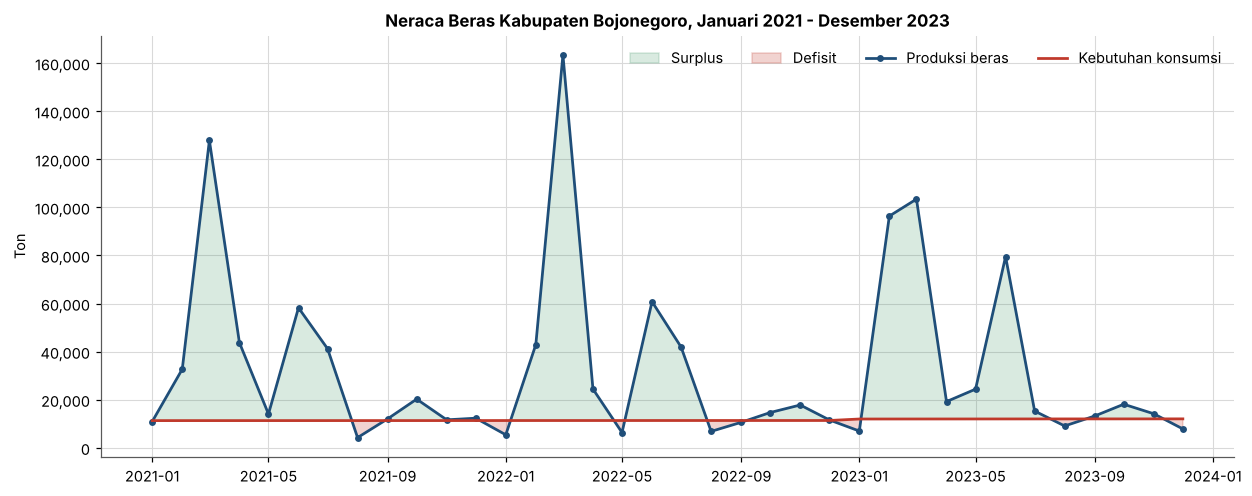

Bulan surplus : 27 dari 36
Bulan defisit : 9 dari 36


In [4]:
# --- 3. GAMBARAN UMUM NERACA BERAS ---
fig, ax = plt.subplots(figsize=(11.5, 4.6))

ax.fill_between(df.index, df.Produksi_Beras_Ton, df.Konsumsi_Beras_Ton,
                where=df.Produksi_Beras_Ton >= df.Konsumsi_Beras_Ton,
                color=HIJAU, alpha=0.18, interpolate=True, label='Surplus')
ax.fill_between(df.index, df.Produksi_Beras_Ton, df.Konsumsi_Beras_Ton,
                where=df.Produksi_Beras_Ton < df.Konsumsi_Beras_Ton,
                color=MERAH, alpha=0.22, interpolate=True, label='Defisit')
ax.plot(df.index, df.Produksi_Beras_Ton, color=BIRU, lw=1.8, marker='o',
        markersize=3.5, label='Produksi beras')
ax.plot(df.index, df.Konsumsi_Beras_Ton, color=MERAH, lw=1.8, label='Kebutuhan konsumsi')

ax.set_title('Neraca Beras Kabupaten Bojonegoro, Januari 2021 - Desember 2023')
ax.set_ylabel('Ton')
ax.yaxis.set_major_formatter(ribuan)
ax.legend(ncol=4, loc='upper right')
fig.tight_layout()
plt.show()

n_defisit = int((df.Status == 'Defisit').sum())
print(f'Bulan surplus : {len(df) - n_defisit} dari {len(df)}')
print(f'Bulan defisit : {n_defisit} dari {len(df)}')

In [5]:
# --- 4. PENAPISAN VARIABEL ---
# ADF  : H0 = ada unit root  -> p > 0,05 berarti tidak stasioner
# KPSS : H0 = deret stasioner -> p < 0,05 berarti tidak stasioner

def periksa(seri):
    p_adf = adfuller(seri, autolag='AIC')[1]
    p_kpss = kpss(seri, regression='c', nlags='auto')[1]
    if p_adf > 0.05 and p_kpss < 0.05:
        kesimpulan = 'TIDAK STASIONER'
    elif p_adf <= 0.05 and p_kpss >= 0.05:
        kesimpulan = 'stasioner'
    else:
        kesimpulan = 'ambigu'
    return {'ADF p': p_adf, 'KPSS p': p_kpss, 'Kesimpulan': kesimpulan,
            'Koef. variasi': seri.std() / seri.mean(),
            'ACF lag 12': acf(seri, nlags=13)[12]}


penapisan = pd.DataFrame({v: periksa(df[v]) for v in VARIABEL}).T
print(penapisan.to_string(float_format=lambda x: f'{x:.4f}'))

                     ADF p KPSS p       Kesimpulan Koef. variasi ACF lag 12
Luas_Panen_Ha       0.0000 0.1000        stasioner        1.0808     0.6164
Produksi_Gabah_Ton  0.0000 0.1000        stasioner        1.1223     0.6204
Produksi_Beras_Ton  0.0000 0.1000        stasioner        1.1223     0.6204
Konsumsi_Beras_Ton  0.8910 0.0171  TIDAK STASIONER        0.0278    -0.1426
Surplus_Defisit_Ton 0.0000 0.1000        stasioner        1.7151     0.6204


/tmp/ipykernel_136/3505616076.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  p_kpss = kpss(seri, regression='c', nlags='auto')[1]
/tmp/ipykernel_136/3505616076.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  p_kpss = kpss(seri, regression='c', nlags='auto')[1]
/tmp/ipykernel_136/3505616076.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  p_kpss = kpss(seri, regression='c', nlags='auto')[1]
/tmp/ipykernel_136/3505616076.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  p_kpss = kpss(seri, regre

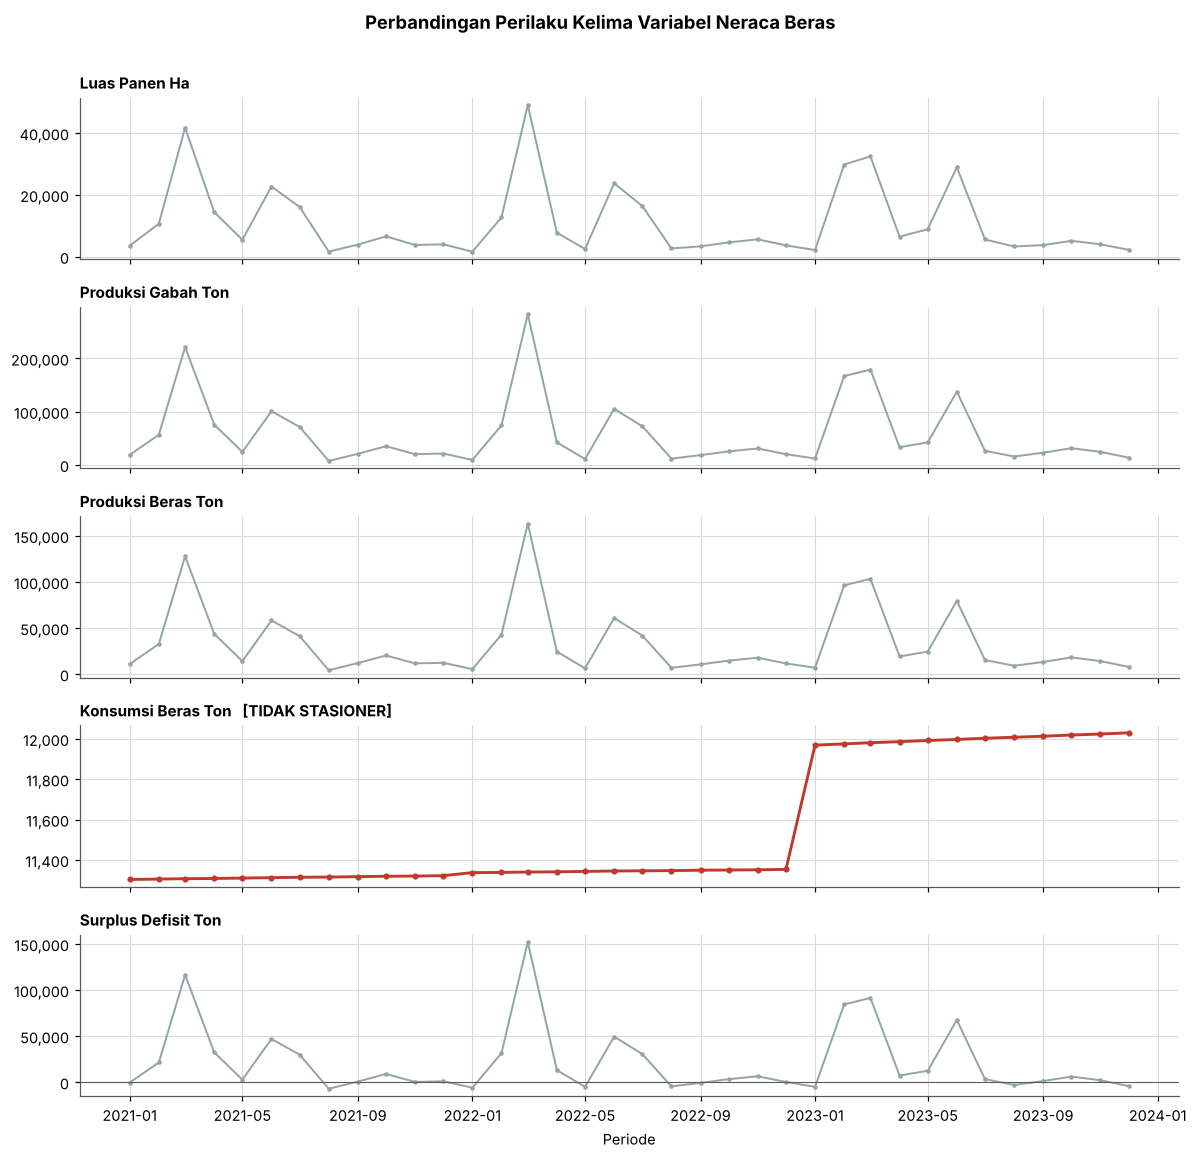

In [6]:
fig, axes = plt.subplots(5, 1, figsize=(11, 10.5), sharex=True)
for ax, v in zip(axes, VARIABEL):
    tidak_stasioner = penapisan.loc[v, 'Kesimpulan'] == 'TIDAK STASIONER'
    ax.plot(df.index, df[v], color=MERAH if tidak_stasioner else ABU,
            lw=1.9 if tidak_stasioner else 1.3,
            marker='o', markersize=3 if tidak_stasioner else 2)
    if df[v].min() < 0:
        ax.axhline(0, color='#595959', lw=0.7)
    tanda = '   [TIDAK STASIONER]' if tidak_stasioner else ''
    ax.set_title(f"{v.replace('_', ' ')}{tanda}", loc='left', fontsize=10)
    ax.yaxis.set_major_formatter(ribuan)
axes[-1].set_xlabel('Periode')
fig.suptitle('Perbandingan Perilaku Kelima Variabel Neraca Beras',
             fontsize=12, fontweight='bold', y=0.998)
fig.tight_layout(rect=[0, 0, 1, 0.99])
plt.show()

In [7]:
# --- 5. VARIABEL TERPILIH ---
VAR = 'Konsumsi_Beras_Ton'
s = df[VAR].asfreq('MS')

print(f'Variabel   : {VAR}')
print(f'Observasi  : {len(s)}')
print(f'Awal       : {s.iloc[0]:,.0f} ton ({s.index[0]:%B %Y})')
print(f'Akhir      : {s.iloc[-1]:,.0f} ton ({s.index[-1]:%B %Y})')
print(f'Perubahan  : {(s.iloc[-1]/s.iloc[0]-1)*100:+.2f}%')
print(f'Rata-rata  : {s.mean():,.0f} ton')
print(f'Koef. var. : {s.std()/s.mean():.4f}')

Variabel   : Konsumsi_Beras_Ton
Observasi  : 36
Awal       : 11,303 ton (January 2021)
Akhir      : 12,030 ton (December 2023)
Perubahan  : +6.43%
Rata-rata  : 11,552 ton
Koef. var. : 0.0278


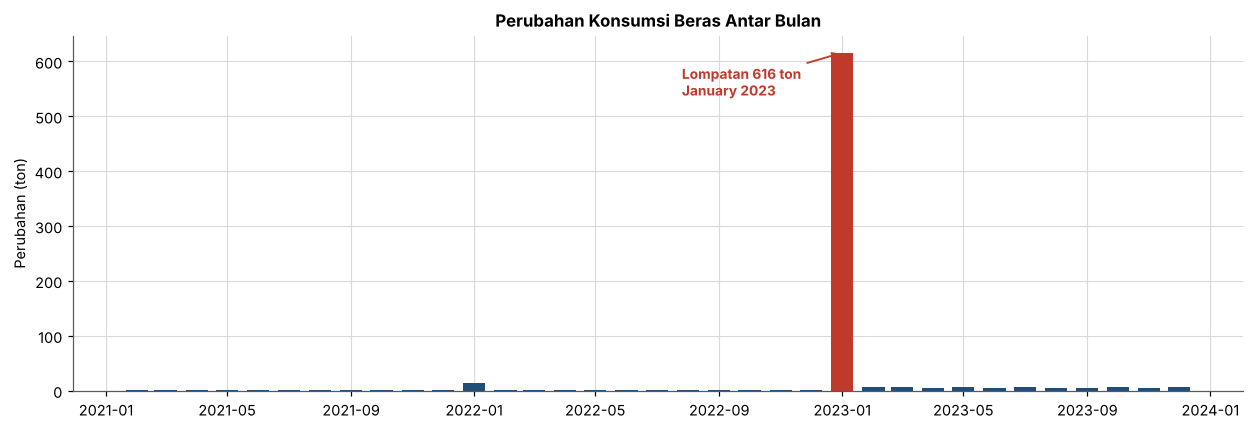

Perubahan bulanan normal : 1 - 15 ton
Lompatan terbesar        : 616 ton pada January 2023
Rasio terhadap normal    : 189 kali


In [8]:
# --- 6. PEMERIKSAAN PATAHAN STRUKTURAL ---
selisih = s.diff().dropna()
lompatan = selisih.idxmax()

fig, ax = plt.subplots(figsize=(11.5, 4))
ax.bar(selisih.index, selisih.values, width=22,
       color=[MERAH if v > 50 else BIRU for v in selisih])
ax.set_title('Perubahan Konsumsi Beras Antar Bulan')
ax.set_ylabel('Perubahan (ton)')
ax.yaxis.set_major_formatter(ribuan)
ax.annotate(f'Lompatan {selisih.max():,.0f} ton\n{lompatan:%B %Y}',
            xy=(lompatan, selisih.max()), xytext=(-105, -28),
            textcoords='offset points', fontsize=9, color=MERAH,
            fontweight='bold', arrowprops=dict(arrowstyle='->', color=MERAH, lw=1.2))
fig.tight_layout()
plt.show()

biasa = selisih[selisih < 50]
print(f'Perubahan bulanan normal : {biasa.min():,.0f} - {biasa.max():,.0f} ton')
print(f'Lompatan terbesar        : {selisih.max():,.0f} ton pada {lompatan:%B %Y}')
print(f'Rasio terhadap normal    : {selisih.max()/biasa.mean():,.0f} kali')

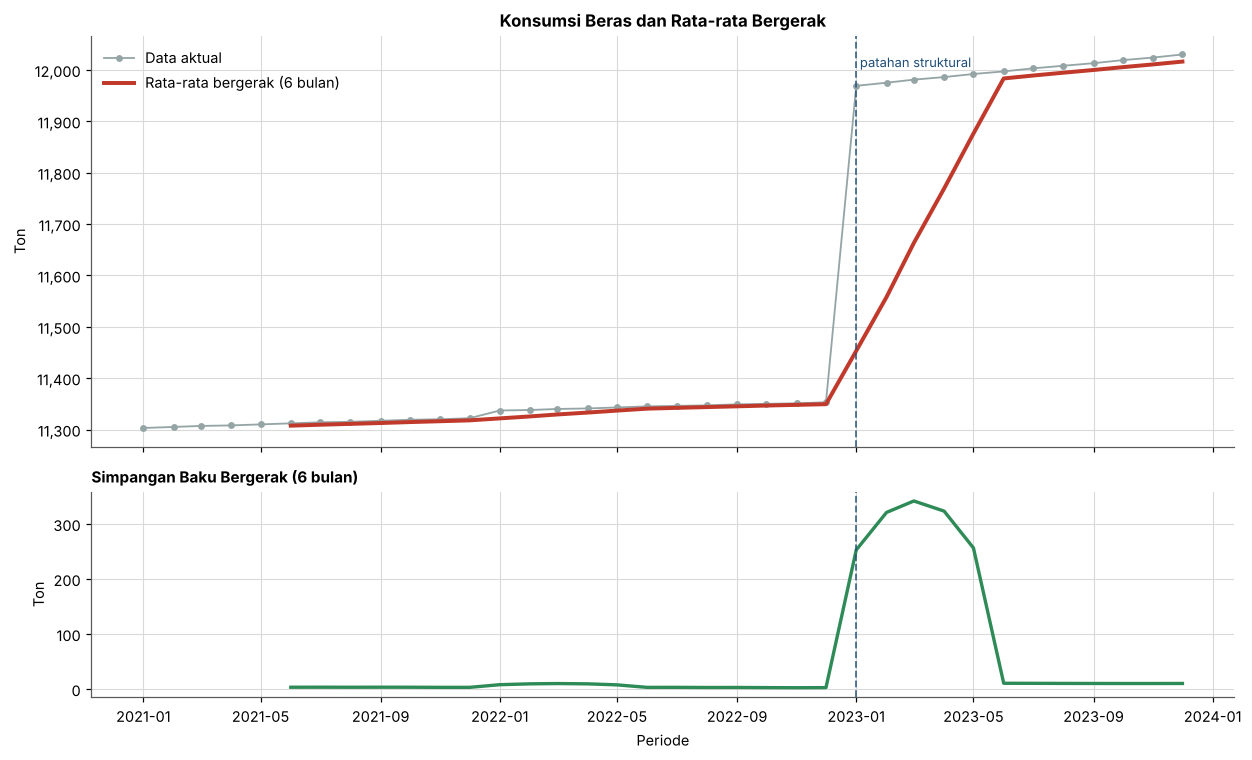

Rata-rata 6 bulan pertama : 11,308 ton
Rata-rata 6 bulan terakhir: 12,016 ton


In [9]:
# --- 7. ROLLING STATISTICS ---
JENDELA = 6
rata_gerak = s.rolling(JENDELA).mean()
simpangan_gerak = s.rolling(JENDELA).std()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11.5, 7), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})

ax1.plot(s.index, s.values, color=ABU, lw=1.2, marker='o', markersize=3.5,
         label='Data aktual')
ax1.plot(rata_gerak.index, rata_gerak.values, color=MERAH, lw=2.6,
         label=f'Rata-rata bergerak ({JENDELA} bulan)')
ax1.axvline(lompatan, color=BIRU, ls='--', lw=1.2, alpha=0.8)
ax1.text(lompatan, s.max(), ' patahan struktural', color=BIRU, fontsize=8.5, va='top')
ax1.set_title('Konsumsi Beras dan Rata-rata Bergerak')
ax1.set_ylabel('Ton')
ax1.yaxis.set_major_formatter(ribuan)
ax1.legend(loc='upper left')

ax2.plot(simpangan_gerak.index, simpangan_gerak.values, color=HIJAU, lw=2.2)
ax2.axvline(lompatan, color=BIRU, ls='--', lw=1.2, alpha=0.8)
ax2.set_title(f'Simpangan Baku Bergerak ({JENDELA} bulan)', loc='left', fontsize=10)
ax2.set_ylabel('Ton')
ax2.set_xlabel('Periode')
ax2.yaxis.set_major_formatter(ribuan)

fig.tight_layout()
plt.show()

print(f'Rata-rata 6 bulan pertama : {s.iloc[:6].mean():,.0f} ton')
print(f'Rata-rata 6 bulan terakhir: {s.iloc[-6:].mean():,.0f} ton')

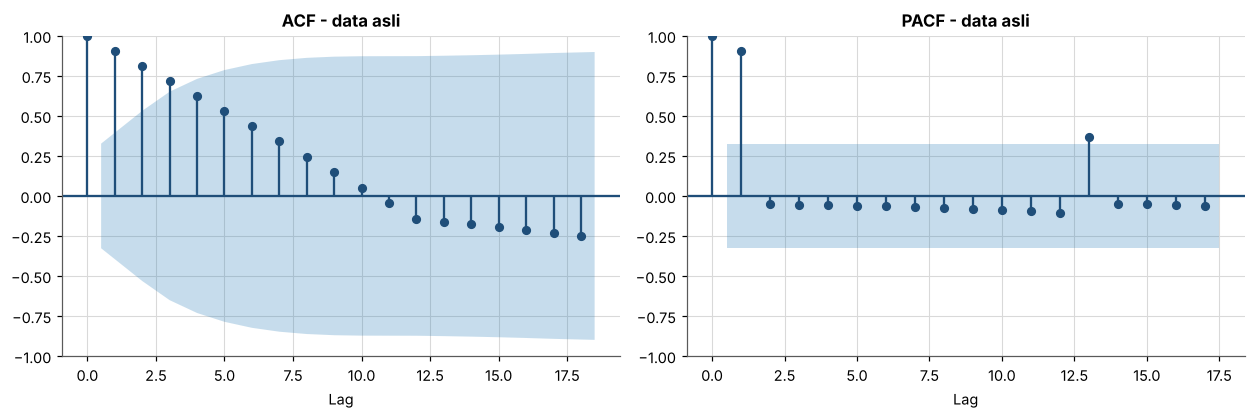

ACF lag 1-6  : 1:+0.91   2:+0.81   3:+0.72   4:+0.63   5:+0.53   6:+0.44
ACF lag 7-12 : 7:+0.34   8:+0.24   9:+0.15   10:+0.05   11:-0.05   12:-0.14


In [10]:
# --- 8. ACF DAN PACF ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.9))
plot_acf(s, lags=18, ax=ax1, color=BIRU, vlines_kwargs={'colors': BIRU})
ax1.set_title('ACF - data asli')
plot_pacf(s, lags=17, ax=ax2, method='ywm', color=BIRU, vlines_kwargs={'colors': BIRU})
ax2.set_title('PACF - data asli')
for ax in (ax1, ax2):
    ax.set_xlabel('Lag')
fig.tight_layout()
plt.show()

nilai_acf = acf(s, nlags=18)
print('ACF lag 1-6  :', '   '.join(f'{i}:{nilai_acf[i]:+.2f}' for i in range(1, 7)))
print('ACF lag 7-12 :', '   '.join(f'{i}:{nilai_acf[i]:+.2f}' for i in range(7, 13)))

In [11]:
# --- 9. UJI FORMAL ADF DAN KPSS ---
def uji_lengkap(seri, nama):
    seri = seri.dropna()
    a = adfuller(seri, autolag='AIC')
    k = kpss(seri, regression='c', nlags='auto')
    putusan_adf = 'TIDAK STASIONER' if a[1] > 0.05 else 'STASIONER'
    putusan_kpss = 'TIDAK STASIONER' if k[1] < 0.05 else 'STASIONER'
    sepakat = putusan_adf == putusan_kpss

    print(f'{nama}  (n = {len(seri)})')
    print(f'  ADF   stat {a[0]:+9.4f} | p {a[1]:.4f} | kritis 5% {a[4]["5%"]:+.4f} | {putusan_adf}')
    print(f'  KPSS  stat {k[0]:9.4f} | p {k[1]:.4f} | kritis 5% {k[3]["5%"]:.4f} | {putusan_kpss}')
    print(f'  -> {"sepakat: " + putusan_adf if sepakat else "tidak sepakat"}')
    print()

    return {'Transformasi': nama, 'ADF p': a[1], 'KPSS p': k[1],
            'Kesimpulan': putusan_adf if sepakat else 'ambigu'}


uji_lengkap(s, 'DATA ASLI (level)')

DATA ASLI (level)  (n = 36)
  ADF   stat   -0.5050 | p 0.8910 | kritis 5% -2.9485 | TIDAK STASIONER
  KPSS  stat    0.6611 | p 0.0171 | kritis 5% 0.4630 | TIDAK STASIONER
  -> sepakat: TIDAK STASIONER



{'Transformasi': 'DATA ASLI (level)',
 'ADF p': 0.891046044376554,
 'KPSS p': np.float64(0.01707886390262598),
 'Kesimpulan': 'TIDAK STASIONER'}

In [12]:
# --- 10. UJI TRANSFORMASI ---
alternatif = [
    ('Data asli (level)', s),
    ('Differencing 1 (d=1)', s.diff()),
    ('Differencing 2 (d=2)', s.diff().diff()),
    ('Log lalu differencing 1', np.log(s).diff()),
]

tabel = pd.DataFrame([uji_lengkap(deret, nama) for nama, deret in alternatif])
tabel = tabel.set_index('Transformasi')
print(tabel.to_string(float_format=lambda x: f'{x:.4f}'))

Data asli (level)  (n = 36)
  ADF   stat   -0.5050 | p 0.8910 | kritis 5% -2.9485 | TIDAK STASIONER
  KPSS  stat    0.6611 | p 0.0171 | kritis 5% 0.4630 | TIDAK STASIONER
  -> sepakat: TIDAK STASIONER

Differencing 1 (d=1)  (n = 35)
  ADF   stat   -5.8161 | p 0.0000 | kritis 5% -2.9512 | STASIONER
  KPSS  stat    0.1284 | p 0.1000 | kritis 5% 0.4630 | STASIONER
  -> sepakat: STASIONER

Differencing 2 (d=2)  (n = 34)
  ADF   stat   -6.5828 | p 0.0000 | kritis 5% -2.9572 | STASIONER
  KPSS  stat    0.5000 | p 0.0417 | kritis 5% 0.4630 | TIDAK STASIONER
  -> tidak sepakat

Log lalu differencing 1  (n = 35)
  ADF   stat   -5.8170 | p 0.0000 | kritis 5% -2.9512 | STASIONER
  KPSS  stat    0.1276 | p 0.1000 | kritis 5% 0.4630 | STASIONER
  -> sepakat: STASIONER

                         ADF p  KPSS p       Kesimpulan
Transformasi                                           
Data asli (level)       0.8910  0.0171  TIDAK STASIONER
Differencing 1 (d=1)    0.0000  0.1000        STASIONER
Differenc

/tmp/ipykernel_136/3109574393.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  k = kpss(seri, regression='c', nlags='auto')
/tmp/ipykernel_136/3109574393.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  k = kpss(seri, regression='c', nlags='auto')


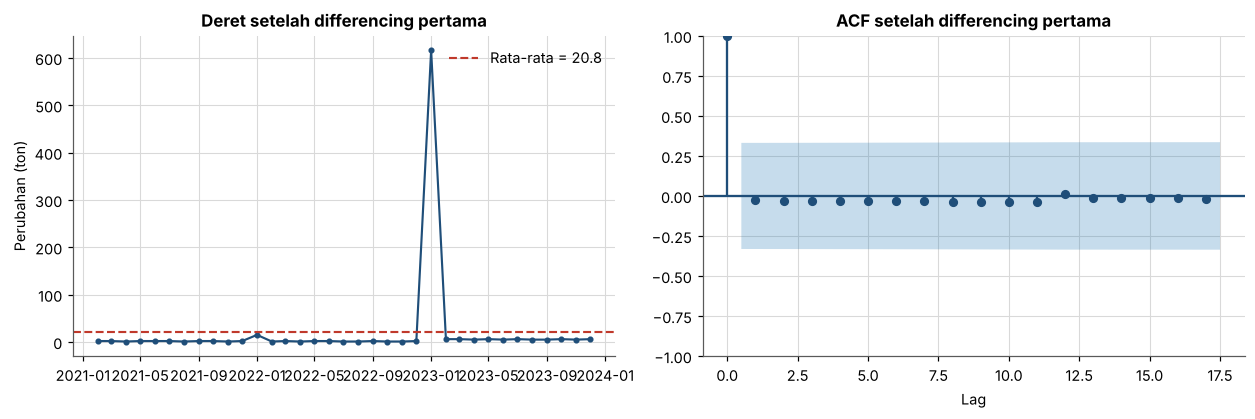

Rata-rata setelah differencing      : 20.77 ton
Simpangan baku setelah differencing : 103.61 ton


In [13]:
# --- 11. SETELAH DIFFERENCING ---
d1 = s.diff().dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.9))
ax1.plot(d1.index, d1.values, color=BIRU, lw=1.4, marker='o', markersize=3)
ax1.axhline(d1.mean(), color=MERAH, ls='--', lw=1.4, label=f'Rata-rata = {d1.mean():,.1f}')
ax1.set_title('Deret setelah differencing pertama')
ax1.set_ylabel('Perubahan (ton)')
ax1.yaxis.set_major_formatter(ribuan)
ax1.legend()

plot_acf(d1, lags=17, ax=ax2, color=BIRU, vlines_kwargs={'colors': BIRU})
ax2.set_title('ACF setelah differencing pertama')
ax2.set_xlabel('Lag')

fig.tight_layout()
plt.show()

print(f'Rata-rata setelah differencing      : {d1.mean():,.2f} ton')
print(f'Simpangan baku setelah differencing : {d1.std():,.2f} ton')

In [14]:
# --- 12. RINGKASAN ---
print('PENAPISAN VARIABEL')
print(penapisan[['ADF p', 'KPSS p', 'Kesimpulan']].to_string(
    float_format=lambda x: f'{x:.4f}'))
print()
print('UJI TRANSFORMASI')
print(tabel.to_string(float_format=lambda x: f'{x:.4f}'))
print()
print('Ordo differencing yang digunakan: d = 1')

PENAPISAN VARIABEL
                     ADF p KPSS p       Kesimpulan
Luas_Panen_Ha       0.0000 0.1000        stasioner
Produksi_Gabah_Ton  0.0000 0.1000        stasioner
Produksi_Beras_Ton  0.0000 0.1000        stasioner
Konsumsi_Beras_Ton  0.8910 0.0171  TIDAK STASIONER
Surplus_Defisit_Ton 0.0000 0.1000        stasioner

UJI TRANSFORMASI
                         ADF p  KPSS p       Kesimpulan
Transformasi                                           
Data asli (level)       0.8910  0.0171  TIDAK STASIONER
Differencing 1 (d=1)    0.0000  0.1000        STASIONER
Differencing 2 (d=2)    0.0000  0.0417           ambigu
Log lalu differencing 1 0.0000  0.1000        STASIONER

Ordo differencing yang digunakan: d = 1
